# 國立陽明交通大學 - 多模態影像資料處理 (MMIP) 2026 Fall
## Assignment 05：多模態深度學習神經網路（影像檢索、圖文多模態分類、CLIP Image Captioning）

- **學生**：林孟霆（`315833033`）
- **作業規範**：課程簡報第 54–56 頁（Quiz 1：30 分、Quiz 2：35 分、Quiz 3：30 分）
- **完整文字報告與結果分析**：請見同目錄 `README.md`

### 在 Google Colab 執行（T4 GPU，約 1 小時）
1. 將 `HW05/` 資料夾壓縮成 `HW05.zip`，拖曳到 Colab 左側的「檔案」區。
2. 「執行階段 → 變更執行階段類型」選 **T4 GPU**。
3. 「執行階段 → 全部執行」。訓練好的模型存在 `Checkpoints/`、抽好的特徵存在 `Data/`，重新執行不會重新訓練。
4. 跑完後執行最後一格下載 `HW05_results.zip`，並用「檔案 → 下載 → 下載 .ipynb」下載這份已執行的 Notebook。

In [1]:
%matplotlib inline
import os, sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    if os.path.exists('/content/HW05.zip'):
        !unzip -q -o /content/HW05.zip -d /content/
    if os.path.exists('/content/HW05/Code'):
        os.chdir('/content/HW05')
    else:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/MMIP/HW05')
    !pip -q install bert-score
sys.path.insert(0, os.getcwd())

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from Code.common import DEVICE
DATA_DIR, CKPT_DIR, OUT_DIR = 'Data', 'Checkpoints', 'Output'
for d in (DATA_DIR, CKPT_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)
pd.set_option('display.max_colwidth', 100)
print(f"Working dir: {os.getcwd()}")
print(f"PyTorch {torch.__version__} | device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == 'cuda' else ''))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.5 MB/s eta 0:00:00
Working dir: /content/HW05
PyTorch 2.11.0+cu130 | device: cuda (Tesla T4)


---
## Quiz 1：影像檢索任務（基礎 20 分 + 進階 10 分）

**簡報要求（第 54 頁）**
- 基礎：（5 分）自行準備影像檢索資料集；（10 分）建立並訓練影像檢索模型；（5 分）成功完成影像檢索推論，展示檢索結果。
- 進階：（5 分）分別使用 CNN 與 Vision Transformer（ViT）作為 Backbone 完成影像檢索；（5 分）比較兩種模型的檢索表現，並整理實驗結果。

**做法**
- **資料集**：CUB-200-2011（200 種鳥、11,788 張）。採用影像檢索研究的標準切法：第 1–90 種訓練、第 91–100 種驗證、第 101–200 種測試，**測試的鳥種在訓練時完全沒看過**。
- **模型**：ImageNet 預訓練 Backbone（ResNet-50 或 ViT-B/16）＋ 512 維嵌入層，輸出 L2 正規化的向量。
- **訓練**：Normalized Softmax（每個訓練類別一個可學習的代表向量，以 cosine 相似度除以溫度 0.05 後做 cross-entropy），讓同種鳥的向量靠近、不同種的遠離。AdamW（backbone lr 1e-4、嵌入層 1e-3）、12 epochs、混合精度；依驗證 Recall@1 保留最佳 epoch。
- **檢索與評估**：每張測試影像當查詢，從其餘所有測試影像中依 cosine 相似度排序；指標為 Recall@1/2/4/8 與 mAP。並以「沒經過檢索訓練的預訓練特徵」作為 baseline。

README.md:   0%|          | 0.00/9.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  286MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  296MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

100%|██████████| 97.8M/97.8M [00:00<00:00, 112MB/s]


  [quiz1_resnet50] epoch  1/12 | loss 2.2175 | val R@1 0.8731 | 40s
  [quiz1_resnet50] epoch  2/12 | loss 0.5491 | val R@1 0.8631 | 40s
  [quiz1_resnet50] epoch  3/12 | loss 0.2687 | val R@1 0.8765 | 40s
  [quiz1_resnet50] epoch  4/12 | loss 0.1395 | val R@1 0.8865 | 40s
  [quiz1_resnet50] epoch  5/12 | loss 0.0792 | val R@1 0.8865 | 40s
  [quiz1_resnet50] epoch  6/12 | loss 0.0465 | val R@1 0.8815 | 40s
  [quiz1_resnet50] epoch  7/12 | loss 0.0372 | val R@1 0.8848 | 39s
  [quiz1_resnet50] epoch  8/12 | loss 0.0298 | val R@1 0.8848 | 39s
  [quiz1_resnet50] epoch  9/12 | loss 0.0226 | val R@1 0.8915 | 40s
  [quiz1_resnet50] epoch 10/12 | loss 0.0195 | val R@1 0.8932 | 40s
  [quiz1_resnet50] epoch 11/12 | loss 0.0189 | val R@1 0.8915 | 40s
  [quiz1_resnet50] epoch 12/12 | loss 0.0171 | val R@1 0.8898 | 39s
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 153MB/s]


  [quiz1_vit_b_16] epoch  1/12 | loss 1.8402 | val R@1 0.8932 | 64s
  [quiz1_vit_b_16] epoch  2/12 | loss 0.6171 | val R@1 0.8932 | 63s
  [quiz1_vit_b_16] epoch  3/12 | loss 0.3636 | val R@1 0.8965 | 63s
  [quiz1_vit_b_16] epoch  4/12 | loss 0.2145 | val R@1 0.8982 | 64s
  [quiz1_vit_b_16] epoch  5/12 | loss 0.1093 | val R@1 0.8965 | 62s
  [quiz1_vit_b_16] epoch  6/12 | loss 0.0677 | val R@1 0.8898 | 63s
  [quiz1_vit_b_16] epoch  7/12 | loss 0.0399 | val R@1 0.8881 | 62s
  [quiz1_vit_b_16] epoch  8/12 | loss 0.0264 | val R@1 0.8815 | 62s
  [quiz1_vit_b_16] epoch  9/12 | loss 0.0228 | val R@1 0.8781 | 63s
  [quiz1_vit_b_16] epoch 10/12 | loss 0.0172 | val R@1 0.8781 | 62s
  [quiz1_vit_b_16] epoch 11/12 | loss 0.0198 | val R@1 0.8831 | 63s
  [quiz1_vit_b_16] epoch 12/12 | loss 0.0136 | val R@1 0.8831 | 62s
                                   model  embedding_dim    R@1    R@2    R@4    R@8    mAP   params  train_minutes  images_per_sec
ResNet-50 (CNN) pretrained (no training)           20

,model,embedding_dim,R@1,R@2,R@4,R@8,mAP,params,train_minutes,images_per_sec
0,ResNet-50 (CNN) pretrained (no training),2048,0.5029,0.6389,0.7557,0.8425,0.2015,23508032,0.00,152.3
1,ResNet-50 (CNN) + retrieval training,512,0.6035,0.7265,0.8256,0.8980,0.3027,24557120,7.94,166.4
2,ViT-B/16 pretrained (no training),768,0.5663,0.6955,0.8003,0.8766,0.2206,85798656,0.00,146.4
3,ViT-B/16 + retrieval training,512,0.6403,0.7591,0.8406,0.9024,0.3317,86192384,12.61,148.7


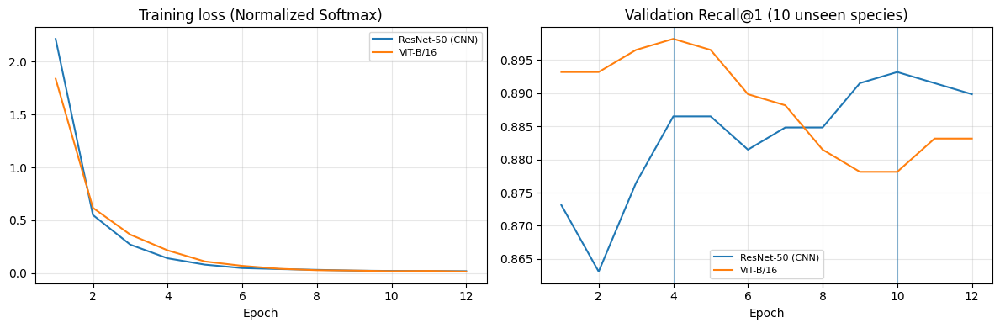

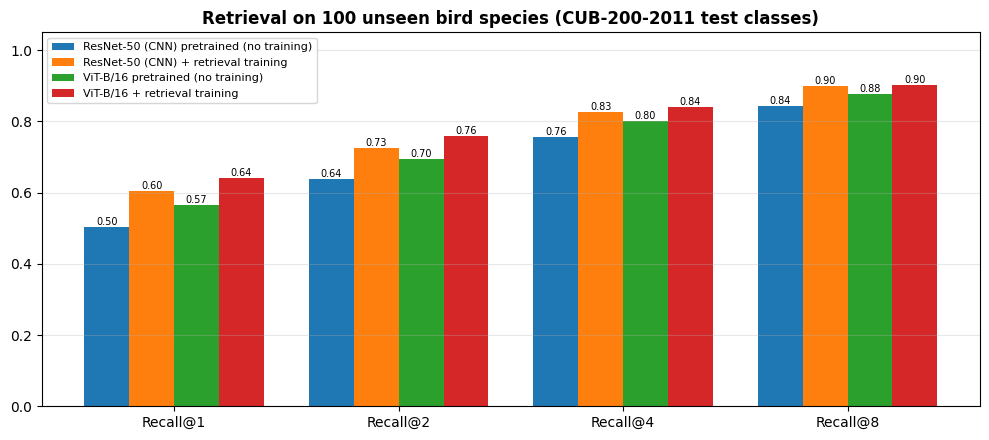

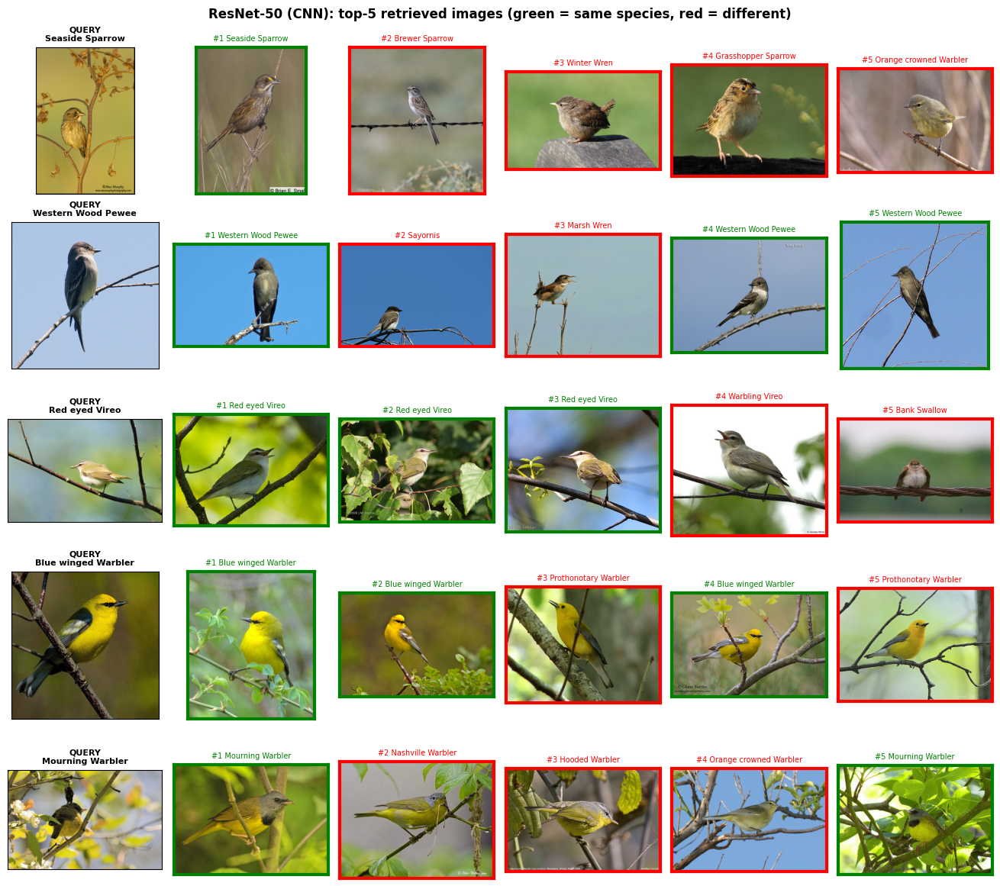

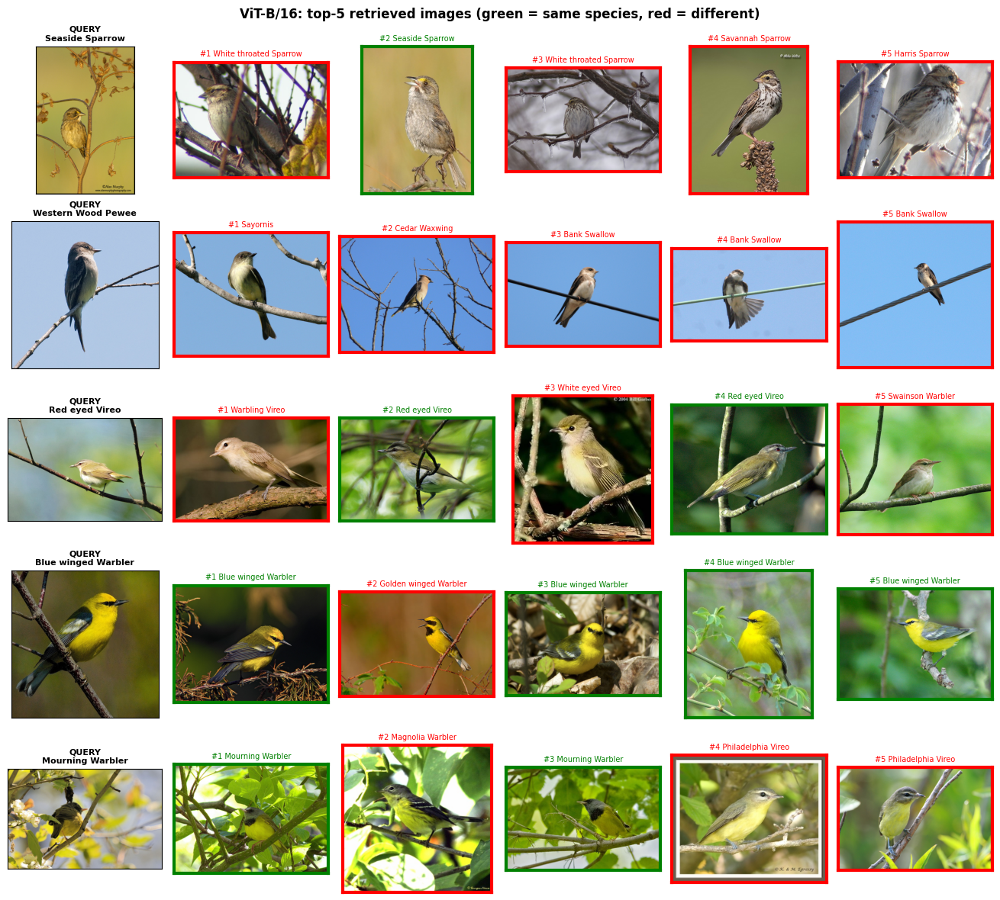

In [ ]:
from Code.data import load_cub
from Code.quiz1_retrieval import run_quiz1
cub = load_cub(DATA_DIR)
q1 = run_quiz1(cub, CKPT_DIR, OUT_DIR)
plt.close('all')
display(q1['table'])
for k in ('history', 'recall', 'examples_resnet50', 'examples_vit_b_16'):
    display(q1['figures'][k])

---
## Quiz 2：多模態深度學習神經網路（基礎 20 分 + 進階 15 分）

**簡報要求（第 55 頁）**
- 基礎：（5 分）自行準備包含影像與文字的多模態訓練資料集；（10 分）使用影像與文字 Backbone 萃取特徵，融合特徵後建立分類模型；（5 分）完成模型訓練，並成功進行多模態分類推論。
- 進階：（10 分）更換至少一種 Backbone 並重新完成模型訓練與推論；（5 分）比較不同 Backbone 組合的模型表現，並整理實驗結果。

**做法**（對應簡報第 44–45 頁的 Match / Not Match 與 Image + Text Feature Fusion）
- **資料集**：由 Flickr8k 自行建立圖文配對。每張影像配上自己的 5 句描述（標籤 1，相符）與 5 句其他隨機影像的描述（標籤 0，不相符）：訓練 60,000 對、驗證 10,000 對、測試 10,000 對，正負各半。
- **模型**：凍結的影像 Backbone 與文字 Backbone 各自萃取特徵 → 各自 LayerNorm → 串接（Concatenate）→ MLP → 相符機率（0～1）。
- **Backbone 組合**：ResNet-50 + BERT（基準）、ViT-B/16 + BERT（換影像 Backbone）、CLIP 影像 + BERT、CLIP 影像 + CLIP 文字（圖文已對齊的特徵空間）。
- **訓練**：AdamW（lr 1e-3）、20 epochs、BCE；依驗證 ROC-AUC 保留最佳 epoch。測試指標：Accuracy、Precision、Recall、F1、ROC-AUC。
- **困難測試集**：隨機抽的不相符描述通常和影像差很多，容易分辨。另外建立一組困難測試題：不相符的描述改從「主角相同」的其他影像挑（例如狗的照片配上另一張狗照片的描述），模型必須看懂動作與場景才分得出來。只用於測試，不參與訓練。

README.md:   0%|          | 0.00/687 [00:00<?, ?B/s]

data/train-00000-of-00002-2f8f6bfa852eac(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00000-of-00002-2f8f6bfa852eac(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-2173151d8cd6c7(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00001-of-00002-2173151d8cd6c7(…): downloading bytes:           |  0.00B            

...

[features] validation: img_clip (1000, 512), img_resnet50 (1000, 2048), img_vit_b_16 (1000, 768), txt_bert (5000, 768), txt_clip (5000, 512) | 50s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[features] test: img_clip (1000, 512), img_resnet50 (1000, 2048), img_vit_b_16 (1000, 768), txt_bert (5000, 768), txt_clip (5000, 512) | 48s
train     : 6000 images -> 60000 pairs (50% match)
validation: 1000 images -> 10000 pairs (50% match)
test      : 1000 images -> 10000 pairs (50% match)
test_hard : 10000 pairs (negatives share the main subject of the true caption)
  [ResNet-50 + BERT] best epoch 19, val AUC 0.9603, 6.9s
  [ViT-B/16 + BERT] best epoch 11, val AUC 0.9538, 5.3s
  [CLIP-image + BERT] best epoch 18, val AUC 0.9797, 5.6s
  [CLIP-image + CLIP-text] best epoch 19, val AUC 0.9902, 5.1s
             backbones  image_dim  text_dim  Accuracy  Precision  Recall     F1  ROC-AUC  Accuracy (hard test)  ROC-AUC (hard test)  best_epoch  fusion_params
      ResNet-50 + BERT       2048       768    0.8999     0.9115  0.8858 0.8985   0.9585                0.8040               0.8709          19        1513729
       ViT-B/16 + BERT        768       768    0.8833     0.8995  0.8630 0.

,backbones,image_dim,text_dim,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy (hard test),ROC-AUC (hard test),best_epoch,fusion_params
0,ResNet-50 + BERT,2048,768,0.8999,0.9115,0.8858,0.8985,0.9585,0.8040,0.8709,19,1513729
1,ViT-B/16 + BERT,768,768,0.8833,0.8995,0.8630,0.8809,0.9542,0.7898,0.8618,11,855809
2,CLIP-image + BERT,512,768,0.9325,0.9359,0.9286,0.9322,0.9776,0.8365,0.9056,18,724225
3,CLIP-image + CLIP-text,512,512,0.9579,0.9556,0.9604,0.9580,0.9901,0.8904,0.9542,19,592641


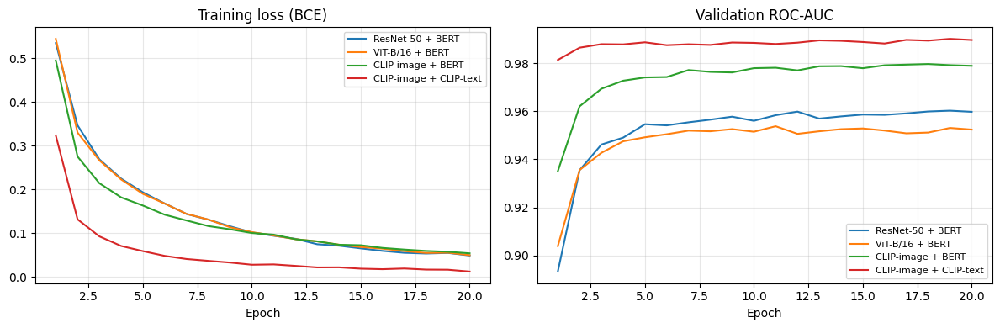

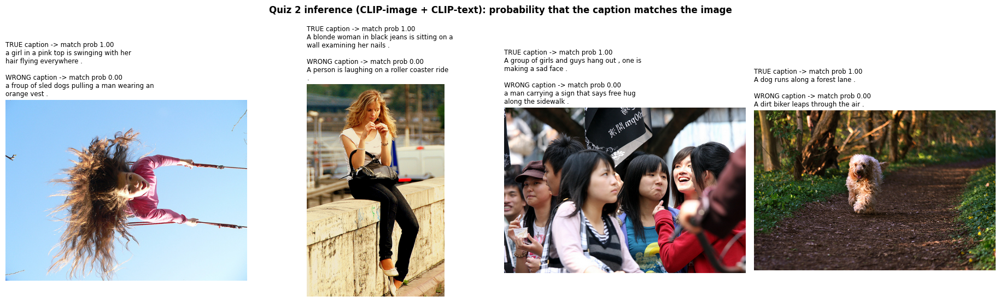

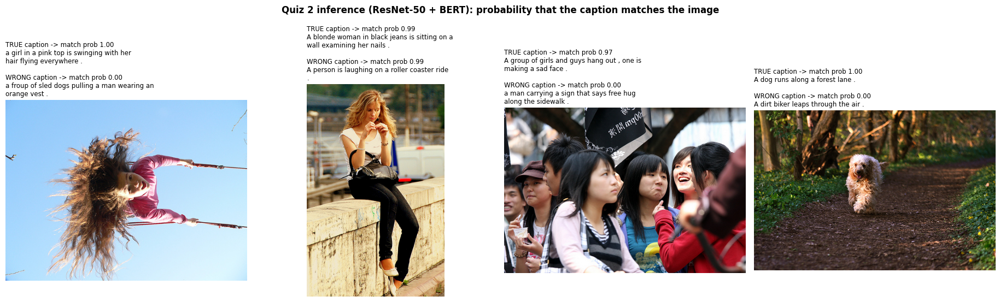

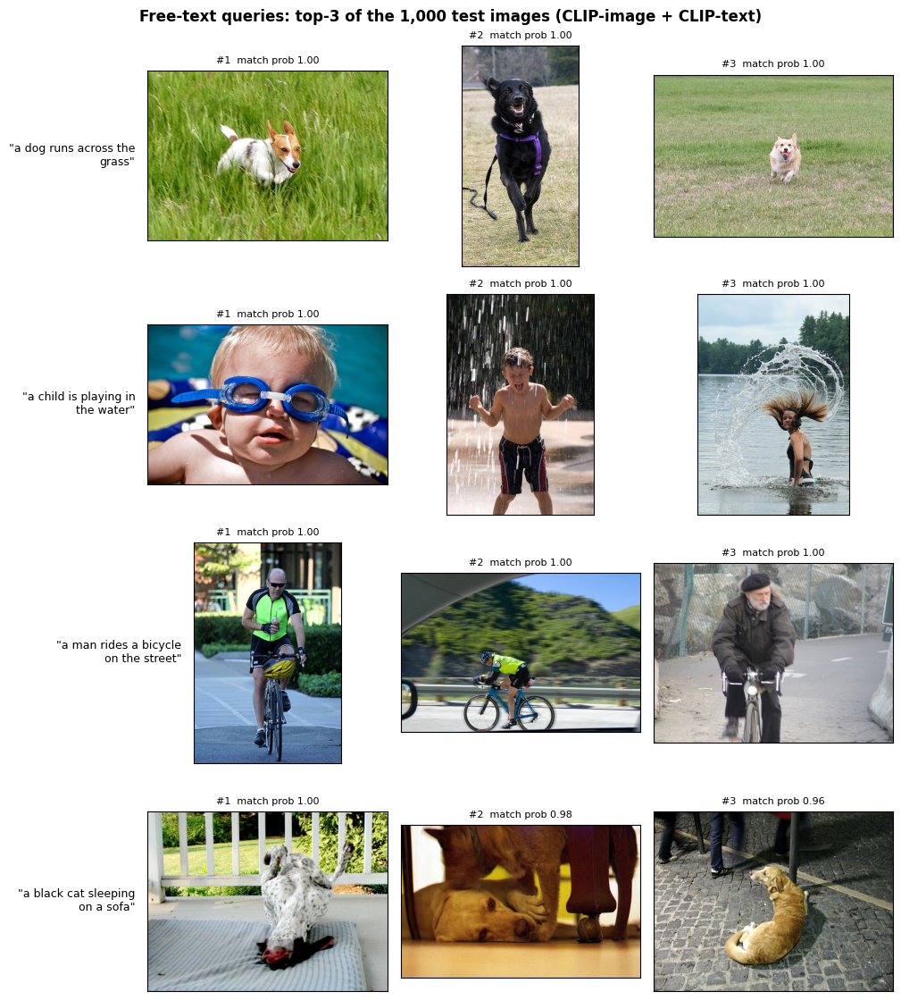

自訂文字 × 測試影像的相符機率：


,query text,rank,test_index,match prob,images above 0.5,a human caption of this image
0,a dog runs across the grass,1,568,1.0000,60,A medium sized brown and white streaked dog is running through tall grass .
1,a dog runs across the grass,2,685,1.0000,60,A black dog with a purple collar and a black leash runs in the grass .
2,a dog runs across the grass,3,954,0.9998,60,A dog with a blue ball running in a field .
3,a child is playing in the water,1,933,0.9999,43,A child wearing swim goggles .
4,a child is playing in the water,2,185,0.9998,43,a boy enjoys a rain shower .
5,a child is playing in the water,3,322,0.9995,43,A girl is shaking the water out of her hair .
6,a man rides a bicycle on the street,1,618,1.0000,16,a biker enjoys a coffee .
7,a man rides a bicycle on the street,2,384,1.0000,16,A bike rider in green jersey races along a road .
8,a man rides a bicycle on the street,3,934,0.9991,16,A man in a beret rides a bicycle down the street .
9,a black cat sleeping on a sofa,1,12,1.0000,4,A dog lays on a mattress on the porch .


In [2]:
from Code.data import load_flickr8k
from Code.quiz2_multimodal import run_quiz2
flickr = load_flickr8k(DATA_DIR)
q2 = run_quiz2(flickr, DATA_DIR, CKPT_DIR, OUT_DIR)
plt.close('all')
display(q2['table'])
for k in ('history', 'examples', 'examples_baseline', 'custom'):
    display(q2['figures'][k])
print('自訂文字 × 測試影像的相符機率：')
display(q2['custom'])

---
## Quiz 3：CLIP Image Captioning（基礎 20 分 + 進階 10 分）

**簡報要求（第 56 頁）**
- 基礎：（5 分）完成資料準備，可使用 Week 4 的 Image Captioning 資料集；（10 分）使用 CLIP 作為 Image Encoder，搭配文字 Decoder 建立 Image Captioning 模型；（5 分）完成模型訓練，並成功產生影像描述。
- 進階：（10 分）比較 Week 4 與本次模型的 BLEU、BERTScore 表現，並整理實驗結果。

**做法**
- **資料**：Week 4 的 Flickr8k，同樣的 6,000 / 1,000 / 1,000 切分。
- **Image Encoder**：凍結的 CLIP ViT-B/32，輸出 50 個 768 維 token（[CLS] + 7×7 個 patch）。
- **Text Decoder**：沿用 Week 4 的 LSTM 與 Transformer decoder，從頭訓練。詞彙表、超參數（15 epochs、AdamW lr 3e-4、batch 128）、Greedy／Beam Search（k = 3）、BLEU 與 BERTScore 的計算方式都和 Week 4 完全相同，**唯一的差別是影像編碼器**（Week 4：ImageNet ResNet-50）。
- Week 4 的結果讀自 `Data/week4_test_metrics.csv`（複製自 HW04 的輸出）。

QUIZ 3: CLIP IMAGE CAPTIONING (Flickr8k, compared with Week 4)
Caption vocabulary: 2,533 words (same rule as Week 4: frequency >= 5)
[CLIP features] train: (6000, 50, 768) | 55s
[CLIP features] validation: (1000, 50, 768) | 9s
[CLIP features] test: (1000, 50, 768) | 8s
  [quiz3_clip_lstm] epoch  1/15 | train loss 5.6016 | val loss 4.0930 | val BLEU-4 0.0762 | 9s
  [quiz3_clip_lstm] epoch  2/15 | train loss 3.8554 | val loss 3.5724 | val BLEU-4 0.0915 | 8s
  [quiz3_clip_lstm] epoch  3/15 | train loss 3.4888 | val loss 3.3329 | val BLEU-4 0.0941 | 7s
  [quiz3_clip_lstm] epoch  4/15 | train loss 3.2732 | val loss 3.1784 | val BLEU-4 0.0939 | 7s
  [quiz3_clip_lstm] epoch  5/15 | train loss 3.1177 | val loss 3.0700 | val BLEU-4 0.1092 | 7s
  [quiz3_clip_lstm] epoch  6/15 | train loss 3.0044 | val loss 2.9943 | val BLEU-4 0.1297 | 7s
  [quiz3_clip_lstm] epoch  7/15 | train loss 2.9191 | val loss 2.9447 | val BLEU-4 0.1454 | 8s
  [quiz3_clip_lstm] epoch  8/15 | train loss 2.8544 | val loss 2.

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


                                 encoder             method  BLEU-1  BLEU-2  BLEU-3  BLEU-4  BERTScore_F1
             ImageNet ResNet-50 (Week 4)        LSTM greedy  0.5866  0.4127  0.2787  0.1866        0.5680
             ImageNet ResNet-50 (Week 4)         LSTM beam3  0.6183  0.4414  0.3077  0.2119        0.5838
             ImageNet ResNet-50 (Week 4) Transformer greedy  0.5847  0.4091  0.2784  0.1882        0.5621
             ImageNet ResNet-50 (Week 4)  Transformer beam3  0.6164  0.4373  0.3053  0.2087        0.5803
BLIP-base (pretrained, Week 4 reference)          BLIP-base  0.6420  0.4910  0.3636  0.2672        0.6067
                  CLIP ViT-B/32 (Week 5)        LSTM greedy  0.5828  0.4031  0.2636  0.1737        0.5604
                  CLIP ViT-B/32 (Week 5)         LSTM beam3  0.5980  0.4190  0.2853  0.1931        0.5697
                  CLIP ViT-B/32 (Week 5) Transformer greedy  0.6260  0.4448  0.3038  0.2038        0.5828
                  CLIP ViT-B/32 (Week 5)  Tran

,encoder,method,BLEU-1,BLEU-2,BLEU-3,BLEU-4,BERTScore_F1
0,ImageNet ResNet-50 (Week 4),LSTM greedy,0.5866,0.4127,0.2787,0.1866,0.5680
1,ImageNet ResNet-50 (Week 4),LSTM beam3,0.6183,0.4414,0.3077,0.2119,0.5838
2,ImageNet ResNet-50 (Week 4),Transformer greedy,0.5847,0.4091,0.2784,0.1882,0.5621
3,ImageNet ResNet-50 (Week 4),Transformer beam3,0.6164,0.4373,0.3053,0.2087,0.5803
4,"BLIP-base (pretrained, Week 4 reference)",BLIP-base,0.6420,0.4910,0.3636,0.2672,0.6067
5,CLIP ViT-B/32 (Week 5),LSTM greedy,0.5828,0.4031,0.2636,0.1737,0.5604
6,CLIP ViT-B/32 (Week 5),LSTM beam3,0.5980,0.4190,0.2853,0.1931,0.5697
7,CLIP ViT-B/32 (Week 5),Transformer greedy,0.6260,0.4448,0.3038,0.2038,0.5828
8,CLIP ViT-B/32 (Week 5),Transformer beam3,0.6411,0.4637,0.3240,0.2243,0.5933


,method,BLEU-4 Week 4,BLEU-4 CLIP,BLEU-4 change,BERTScore Week 4,BERTScore CLIP,BERTScore change
0,LSTM greedy,0.1866,0.1737,-0.0129,0.5680,0.5604,-0.0076
1,LSTM beam3,0.2119,0.1931,-0.0188,0.5838,0.5697,-0.0141
2,Transformer greedy,0.1882,0.2038,0.0156,0.5621,0.5828,0.0207
3,Transformer beam3,0.2087,0.2243,0.0156,0.5803,0.5933,0.0130


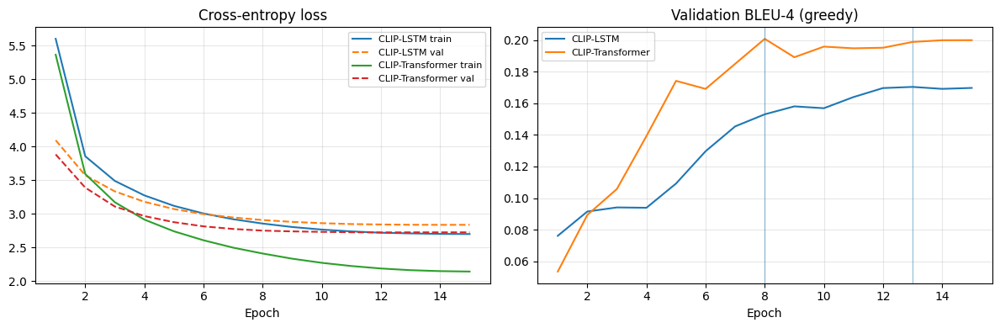

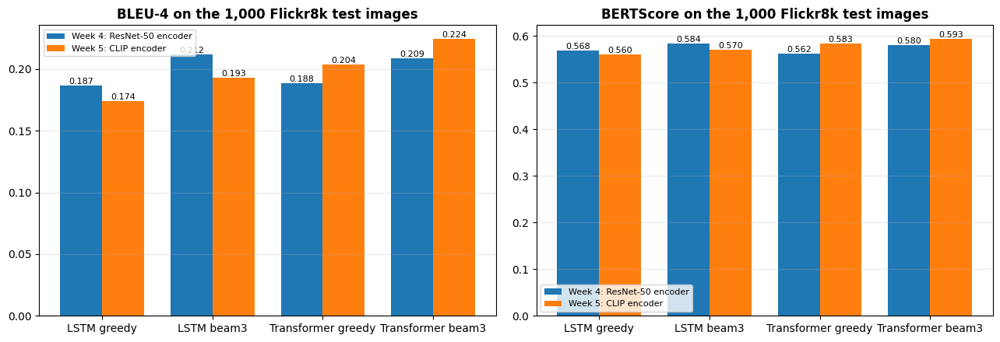

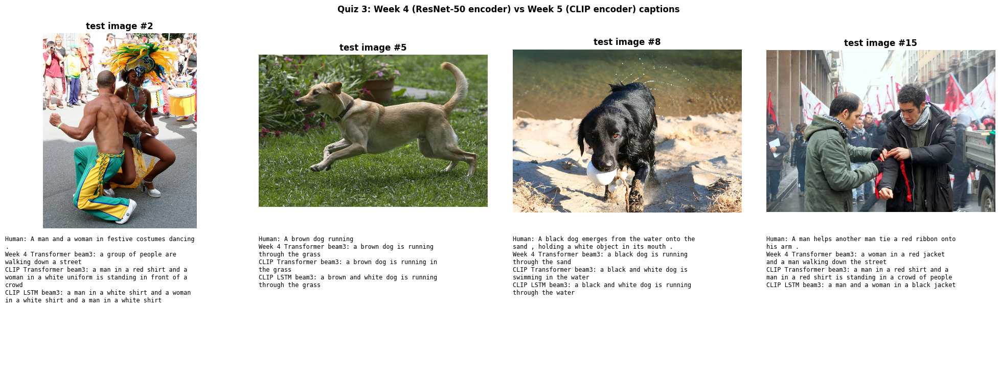

In [ ]:
from Code.quiz3_clip_caption import run_quiz3
q3 = run_quiz3(flickr, DATA_DIR, CKPT_DIR, OUT_DIR)
plt.close('all')
print('Week 4 與 Week 5（CLIP）在 1,000 張測試影像上的表現：')
display(q3['comparison'])
display(q3['delta'])
for k in ('history', 'compare', 'samples'):
    display(q3['figures'][k])

---
## 結果分析

各題的數據解讀、實驗結論與限制說明，整理在同目錄的 `README.md`。

In [3]:
# 打包下載結果（Output/ 與訓練紀錄 Checkpoints/*.json；模型權重與特徵檔太大不打包）
try:
    from google.colab import files
    !zip -q -r /content/HW05_results.zip Output Checkpoints -x "*.pt"
    files.download('/content/HW05_results.zip')
    print('已下載 HW05_results.zip；請另外用「檔案 → 下載 → 下載 .ipynb」下載這份已執行的 Notebook。')
except ImportError:
    print('本機執行：結果已在 Output/ 與 Checkpoints/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

已下載 HW05_results.zip；請另外用「檔案 → 下載 → 下載 .ipynb」下載這份已執行的 Notebook。
